## 1. Imports and Config

In [1]:
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    cross_val_predict, learning_curve
)
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score,
    ConfusionMatrixDisplay
)
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_class_weight
from sklearn.inspection import permutation_importance
import warnings
warnings.filterwarnings('ignore')

artifacts = joblib.load('eda_artifacts.pkl')
df = artifacts['df']
num_features = artifacts['num_features']
iso_anomaly  = artifacts['iso_anomaly']

print('Data loaded from EDA.')

Data loaded from EDA.


---
## 2. Data Preparation

In [ ]:
df_model = df[num_features + ['Type', 'Target']].copy()


df_model['iso_score'] = iso_anomaly

df_model = pd.get_dummies(df_model, columns=['Type'], drop_first=False)

feature_cols = [c for c in df_model.columns if c != 'Target']
X_all = df_model[feature_cols].values
y_all = df_model['Target'].values

X_train_calib, X_test, y_train_calib, y_test = train_test_split(
    X_all, y_all, test_size=0.15, random_state=17, stratify=y_all
)
X_train, X_calib, y_train, y_calib = train_test_split(
    X_train_calib, y_train_calib, test_size=0.176, random_state=17, stratify=y_train_calib
)
# 0.176 * 0.85 ≈ 0.15  ->  train≈70%, calib≈15%, test≈15%

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_calib_sc = scaler.transform(X_calib)
X_test_sc = scaler.transform(X_test)
X_train_calib_sc = scaler.transform(X_train_calib)

classes = np.unique(y_train)
cw = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weight_dict = dict(zip(classes, cw))

print(f'Train: {X_train.shape[0]} samples')
print(f'Calib: {X_calib.shape[0]} samples')
print(f'Test:  {X_test.shape[0]} samples')
print(f'Train failures: {y_train.sum()} ({y_train.mean()*100:.1f}%)')
print(f'Calib failures: {y_calib.sum()} ({y_calib.mean()*100:.1f}%)')
print(f'Test  failures: {y_test.sum()}  ({y_test.mean()*100:.1f}%)')
print(f'\nClass weights: {class_weight_dict}')
print(f'\nFeatures ({len(feature_cols)}): {feature_cols}')

Train: 7004 samples
Calib: 1496 samples
Test:  1500 samples
Train failures: 237 (3.4%)
Calib failures: 51 (3.4%)
Test  failures: 51  (3.4%)

Class weights: {np.int64(0): np.float64(0.5175114526378011), np.int64(1): np.float64(14.776371308016877)}

Features (9): ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'iso_score', 'Type_H', 'Type_L', 'Type_M']


---
## 3. Hyperparameter Tuning - Architecture Search

Best architecture:    (64, 32)
Best alpha (L2):      0.01
Best learning_rate:   0.001
Best CV ROC-AUC:      0.9505


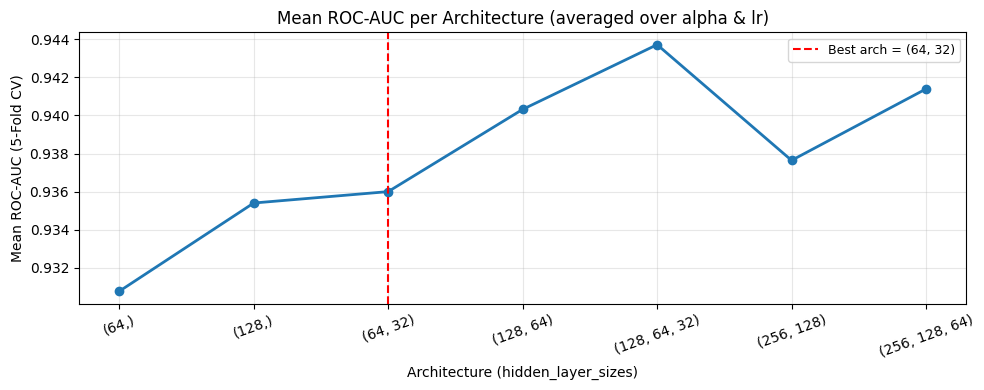

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=17)

architectures = [
    (64,),
    (128,),
    (64, 32),
    (128, 64),
    (128, 64, 32),
    (256, 128),
    (256, 128, 64),
]
alphas          = [1e-4, 1e-3, 1e-2]
learning_rates  = [1e-3, 3e-4]

best_score = -np.inf
best_params = {}
results_grid = []

for arch in architectures:
    for alpha in alphas:
        for lr in learning_rates:
            mlp_pipe = Pipeline([
                ('scaler', StandardScaler()),
                ('mlp', MLPClassifier(
                    hidden_layer_sizes=arch,
                    activation='relu',
                    solver='adam',
                    alpha=alpha,
                    learning_rate_init=lr,
                    max_iter=300,
                    random_state=17,
                    early_stopping=True,
                    validation_fraction=0.1,
                    n_iter_no_change=15
                ))
            ])
            sample_weight_train = np.where(y_train == 1, class_weight_dict[1], class_weight_dict[0])
            fold_scores = []

            for train_idx, valid_idx in cv.split(X_train, y_train):
                X_tr, X_val = X_train[train_idx], X_train[valid_idx]
                y_tr, y_val = y_train[train_idx], y_train[valid_idx]
                sw_tr = sample_weight_train[train_idx]

                mlp_pipe.fit(X_tr, y_tr, mlp__sample_weight=sw_tr)
                y_val_proba = mlp_pipe.predict_proba(X_val)[:, 1]
                fold_scores.append(roc_auc_score(y_val, y_val_proba))

            cv_res = {'test_score': np.array(fold_scores)}
            score = cv_res['test_score'].mean()
            results_grid.append((arch, alpha, lr, score))
            if score > best_score:
                best_score  = score
                best_params = {'arch': arch, 'alpha': alpha, 'lr': lr}

best_arch = best_params['arch']
best_alpha = best_params['alpha']
best_lr    = best_params['lr']

print(f'Best architecture:    {best_arch}')
print(f'Best alpha (L2):      {best_alpha}')
print(f'Best learning_rate:   {best_lr}')
print(f'Best CV ROC-AUC:      {best_score:.4f}')

arch_scores = {}
for arch, alpha, lr, score in results_grid:
    arch_scores.setdefault(str(arch), []).append(score)
arch_means  = [np.mean(v) for v in arch_scores.values()]
arch_labels = list(arch_scores.keys())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(arch_labels, arch_means, marker='o', lw=2)
ax.axvline(
    arch_labels.index(str(best_arch)),
    color='red', linestyle='--', lw=1.5,
    label=f'Best arch = {best_arch}'
)
ax.set_title('Mean ROC-AUC per Architecture (averaged over alpha & lr)')
ax.set_xlabel('Architecture (hidden_layer_sizes)')
ax.set_ylabel('Mean ROC-AUC (5-Fold CV)')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

---
## 4. Training and Basic Evaluation

In [5]:
sample_weight_train = np.where(y_train == 1, class_weight_dict[1], class_weight_dict[0])

mlp = MLPClassifier(
    hidden_layer_sizes=best_arch,
    activation='relu',
    solver='adam',
    alpha=best_alpha,
    learning_rate_init=best_lr,
    max_iter=500,
    random_state=17,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20
)
mlp.fit(X_train_sc, y_train, sample_weight=sample_weight_train)

y_pred  = mlp.predict(X_test_sc)
y_proba = mlp.predict_proba(X_test_sc)[:, 1]

print('- Classification Report -')
print(classification_report(y_test, y_pred, target_names=['No Failure', 'Failure']))

roc_auc  = roc_auc_score(y_test, y_proba)
avg_prec = average_precision_score(y_test, y_proba)
print(f'ROC-AUC: {roc_auc:.4f}')
print(f'Average Precision: {avg_prec:.4f}')
print(f'\nIterations run: {mlp.n_iter_}')
print(f'Best validation score: {mlp.best_validation_score_:.4f}')

- Classification Report -
              precision    recall  f1-score   support

  No Failure       1.00      0.94      0.97      1449
     Failure       0.36      0.92      0.52        51

    accuracy                           0.94      1500
   macro avg       0.68      0.93      0.74      1500
weighted avg       0.98      0.94      0.95      1500

ROC-AUC: 0.9799
Average Precision: 0.7909

Iterations run: 103
Best validation score: 0.9626


---
## 5. Confusion Matrix

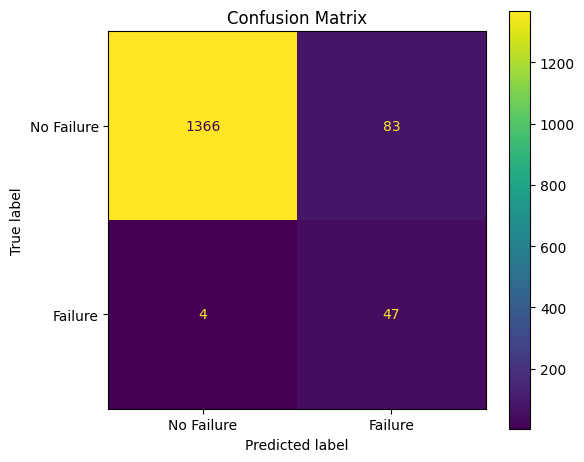


False Alarm Rate: 0.057
Miss Rate: 0.078


In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=['No Failure', 'Failure'])
disp.plot(ax=ax)
ax.set_title('Confusion Matrix')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'\nFalse Alarm Rate: {fp/(fp+tn):.3f}')
print(f'Miss Rate: {fn/(fn+tp):.3f}')

---
## 6. ROC Curve and Precision-Recall Curve

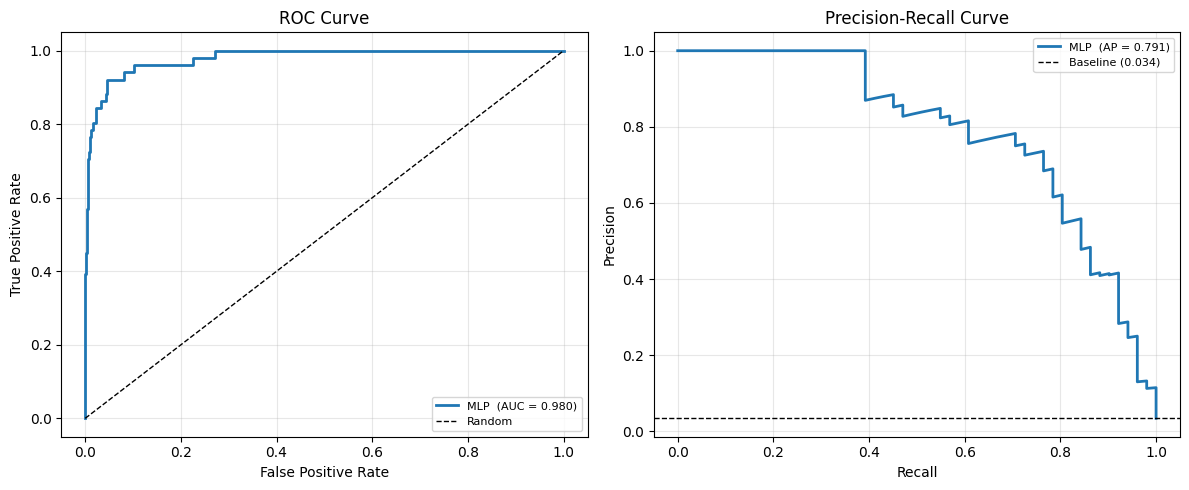

In [7]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
prec, rec, _ = precision_recall_curve(y_test, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC
ax = axes[0]
ax.plot(fpr, tpr, lw=2, label=f'MLP  (AUC = {roc_auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Precision-Recall
ax = axes[1]
ax.plot(rec, prec, lw=2, label=f'MLP  (AP = {avg_prec:.3f})')
baseline = y_test.mean()
ax.axhline(baseline, color='k', linestyle='--', lw=1, label=f'Baseline ({baseline:.3f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 7. Loss Curve

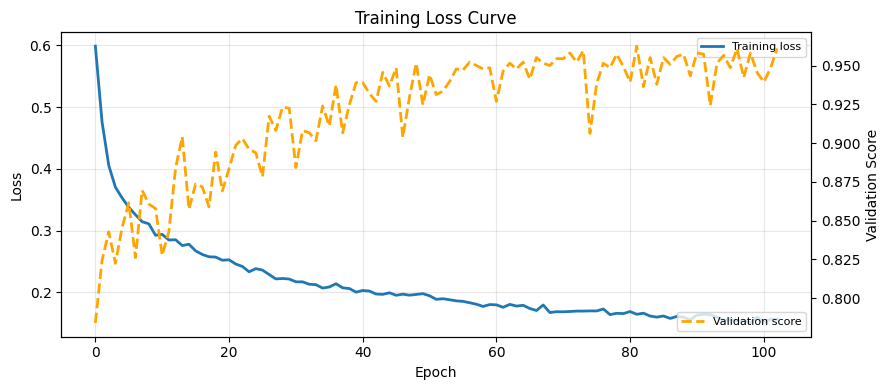

Training converged after 103 epochs (early stopping active)


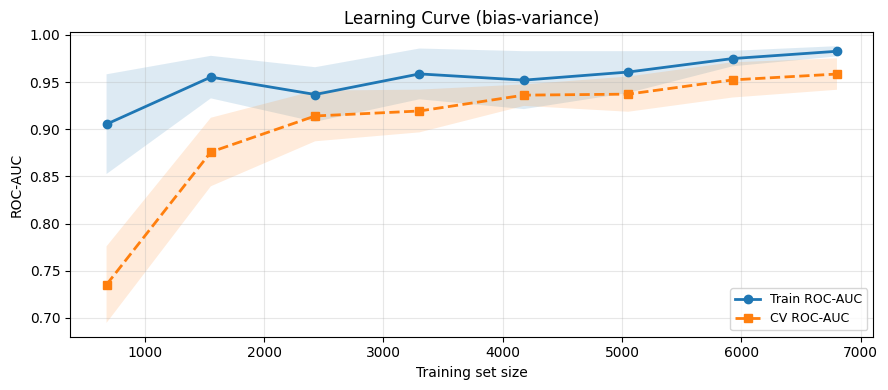

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(mlp.loss_curve_, lw=2, label='Training loss')
if hasattr(mlp, 'validation_scores_') and mlp.validation_scores_ is not None:
    ax2 = ax.twinx()
    ax2.plot(
        mlp.validation_scores_, lw=2,
        color='orange', linestyle='--', label='Validation score'
    )
    ax2.set_ylabel('Validation Score')
    ax2.legend(loc='lower right', fontsize=8)
ax.set_title('Training Loss Curve')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.legend(loc='upper right', fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(f'Training converged after {mlp.n_iter_} epochs (early stopping active)')

lc_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPClassifier(
        hidden_layer_sizes=best_arch,
        activation='relu',
        solver='adam',
        alpha=best_alpha,
        learning_rate_init=best_lr,
        max_iter=500,
        random_state=17,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20
    ))
])

train_sizes, train_scores, val_scores = learning_curve(
    lc_pipeline, X_train_calib, y_train_calib,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=17),
    scoring='roc_auc',
    train_sizes=np.linspace(0.1, 1.0, 8),
    n_jobs=-1,
    fit_params={'mlp__sample_weight':
        np.where(y_train_calib == 1, class_weight_dict[1], class_weight_dict[0])}
)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(train_sizes, train_scores.mean(axis=1), 'o-', lw=2, label='Train ROC-AUC')
ax.fill_between(train_sizes,
                train_scores.mean(axis=1) - train_scores.std(axis=1),
                train_scores.mean(axis=1) + train_scores.std(axis=1), alpha=0.15)
ax.plot(train_sizes, val_scores.mean(axis=1), 's--', lw=2, label='CV ROC-AUC')
ax.fill_between(train_sizes,
                val_scores.mean(axis=1) - val_scores.std(axis=1),
                val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.15)
ax.set_title('Learning Curve (bias-variance)')
ax.set_xlabel('Training set size')
ax.set_ylabel('ROC-AUC')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## 8. Cross-validation (Stratified 5-Fold)

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=17)

mlp_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPClassifier(
        hidden_layer_sizes=best_arch,
        activation='relu',
        solver='adam',
        alpha=best_alpha,
        learning_rate_init=best_lr,
        max_iter=500,
        random_state=17,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20
    ))
])

sample_weight_tc = np.where(y_train_calib == 1, class_weight_dict[1], class_weight_dict[0])

cv_results = cross_validate(
    mlp_pipeline, X_train_calib, y_train_calib, cv=cv,
    scoring=['roc_auc', 'average_precision', 'f1', 'recall', 'precision'],
    return_train_score=False,
    params={'mlp__sample_weight': sample_weight_tc}
)

metrics = {
    'ROC-AUC': cv_results['test_roc_auc'],
    'Avg Precision': cv_results['test_average_precision'],
    'F1 (Failure)': cv_results['test_f1'],
    'Recall (Failure)': cv_results['test_recall'],
    'Precision (Failure)': cv_results['test_precision'],
}

print('- Cross-Validation Results (5-Fold on train+calib set) -')
print(f'{"Metric":<23} {"Mean":>8} {"Std":>8} {"Min":>8} {"Max":>8}')
print('-' * 60)
for name, vals in metrics.items():
    print(f'{name:<25} {vals.mean():>8.4f} {vals.std():>8.4f} {vals.min():>8.4f} {vals.max():>8.4f}')

- Cross-Validation Results (5-Fold on train+calib set) -
Metric                      Mean      Std      Min      Max
------------------------------------------------------------
ROC-AUC                     0.9585   0.0167   0.9313   0.9826
Avg Precision               0.6606   0.0622   0.5733   0.7212
F1 (Failure)                0.4225   0.0680   0.3446   0.5241
Recall (Failure)            0.8546   0.0774   0.7586   0.9825
Precision (Failure)         0.2856   0.0642   0.2143   0.3769


---
## 9. MLP Calibration

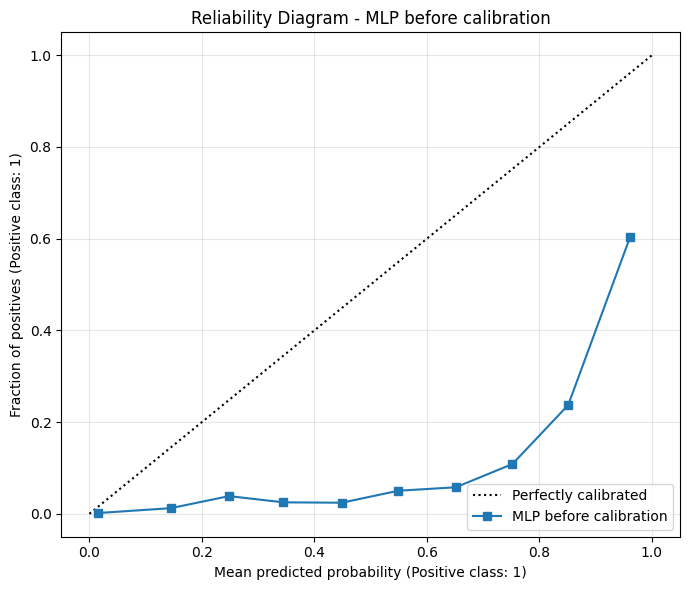

Points above the diagonal -> the model underestimates
Points below the diagonal -> the model overestimates


In [10]:
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay

sample_weight_tc = np.where(y_train_calib == 1, class_weight_dict[1], class_weight_dict[0])

pipeline_cv = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPClassifier(
        hidden_layer_sizes=best_arch,
        activation='relu',
        solver='adam',
        alpha=best_alpha,
        learning_rate_init=best_lr,
        max_iter=500,
        random_state=17,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20
    ))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=17)
y_proba_cv = np.zeros(len(y_train_calib), dtype=float)

for train_idx, val_idx in cv.split(X_train_calib, y_train_calib):
    X_tr, X_val = X_train_calib[train_idx], X_train_calib[val_idx]
    y_tr = y_train_calib[train_idx]
    sw_tr = sample_weight_tc[train_idx]
    pipeline_cv.fit(X_tr, y_tr, mlp__sample_weight=sw_tr)
    y_proba_cv[val_idx] = pipeline_cv.predict_proba(X_val)[:, 1]

fig, ax = plt.subplots(figsize=(7, 6))
CalibrationDisplay.from_predictions(
    y_train_calib, y_proba_cv,
    n_bins=10, ax=ax,
    name='MLP before calibration'
)
ax.set_title('Reliability Diagram - MLP before calibration')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('Points above the diagonal -> the model underestimates')
print('Points below the diagonal -> the model overestimates')

---
## 10. Temperature Scaling - Calibration
- T > 1 -> model was overconfident -> scaling sharpens distribution.
- T < 1 -> model was underconfident -> scaling concentrates distribution.

In [12]:
import scipy.optimize as opt
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import log_loss, brier_score_loss

def get_logits(mlp, X):
    proba = mlp.predict_proba(X)
    proba = np.clip(proba, 1e-7, 1 - 1e-7)
    return np.log(proba[:, 1]) - np.log(proba[:, 0])


def temperature_scale_proba(logits, T):
    return 1.0 / (1.0 + np.exp(-logits / T))


def fit_temperature(logits_calib, y_calib):
    def nll(log_T):
        T = np.exp(log_T[0]) # optimise log(T) so T stays > 0
        p = temperature_scale_proba(logits_calib, T)
        return log_loss(y_calib, p)

    result = opt.minimize(nll, x0=[0.0], method='Nelder-Mead',
                          options={'xatol': 1e-6, 'fatol': 1e-8, 'maxiter': 5000})
    T_opt = np.exp(result.x[0])
    return T_opt


sample_weight_train = np.where(y_train == 1, class_weight_dict[1], class_weight_dict[0])
sample_weight_tc    = np.where(y_train_calib == 1, class_weight_dict[1], class_weight_dict[0])

base_mlp = MLPClassifier(
    hidden_layer_sizes=best_arch,
    activation='relu',
    solver='adam',
    alpha=best_alpha,
    learning_rate_init=best_lr,
    max_iter=500,
    random_state=17,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20
)
base_mlp.fit(X_train_sc, y_train, sample_weight=sample_weight_train)

logits_calib = get_logits(base_mlp, X_calib_sc)
T_opt = fit_temperature(logits_calib, y_calib)

logits_test = get_logits(base_mlp, X_test_sc)

y_proba          = base_mlp.predict_proba(X_test_sc)[:, 1]
y_proba_temp     = temperature_scale_proba(logits_test, T_opt)

base_mlp_full = MLPClassifier(
    hidden_layer_sizes=best_arch,
    activation='relu',
    solver='adam',
    alpha=best_alpha,
    learning_rate_init=best_lr,
    max_iter=500,
    random_state=17,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20
)
base_mlp_full.fit(X_train_calib_sc, y_train_calib, sample_weight=sample_weight_tc)

print(f'Fitted temperature T = {T_opt:.4f}')
print(f'T > 1: model was overconfident -> scaling spreads probabilities (lowers confidence)')
print(f'T < 1: model was underconfident -> scaling concentrates probabilities')
print()
print(f'Uncalibrated - mean p̂: {y_proba.mean():.4f}  std: {y_proba.std():.4f}')
print(f'Temp-Scaled - mean p̂: {y_proba_temp.mean():.4f}  std: {y_proba_temp.std():.4f}')
print(f'Actual failure rate (test): {y_test.mean():.4f}')


Fitted temperature T = 1.0429
T > 1: model was overconfident -> scaling spreads probabilities (lowers confidence)
T < 1: model was underconfident -> scaling concentrates probabilities

Uncalibrated - mean p̂: 0.1122  std: 0.2330
Temp-Scaled - mean p̂: 0.1142  std: 0.2316
Actual failure rate (test): 0.0340


---
## 11. Feature Importance (Permutation)

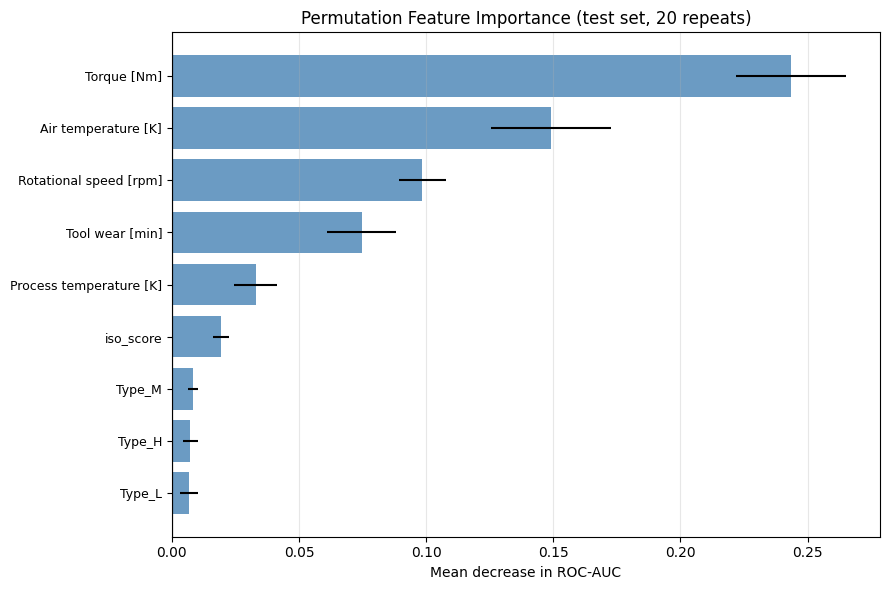

Feature                          Importance      Std
----------------------------------------------------
Torque [Nm]                          0.2434   0.0217
Air temperature [K]                  0.1491   0.0235
Rotational speed [rpm]               0.0984   0.0092
Tool wear [min]                      0.0746   0.0136
Process temperature [K]              0.0330   0.0085
iso_score                            0.0194   0.0032
Type_M                               0.0083   0.0019
Type_H                               0.0073   0.0030
Type_L                               0.0068   0.0035


In [13]:
perm_imp = permutation_importance(
    base_mlp_full, X_test_sc, y_test,
    n_repeats=20, random_state=17,
    scoring='roc_auc'
)

sorted_idx = perm_imp.importances_mean.argsort()[::-1]
top_n = min(20, len(feature_cols))

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    range(top_n),
    perm_imp.importances_mean[sorted_idx[:top_n]][::-1],
    xerr=perm_imp.importances_std[sorted_idx[:top_n]][::-1],
    align='center', color='steelblue', alpha=0.8
)
ax.set_yticks(range(top_n))
ax.set_yticklabels([feature_cols[i] for i in sorted_idx[:top_n]][::-1], fontsize=9)
ax.set_xlabel('Mean decrease in ROC-AUC')
ax.set_title('Permutation Feature Importance (test set, 20 repeats)')
ax.axvline(0, color='black', lw=0.8)
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

print(f'{"Feature":<30} {"Importance":>12} {"Std":>8}')
print('-' * 52)
for i in sorted_idx[:top_n]:
    print(f'{feature_cols[i]:<30} {perm_imp.importances_mean[i]:>12.4f} {perm_imp.importances_std[i]:>8.4f}')


---
## 12. Reliability Diagram

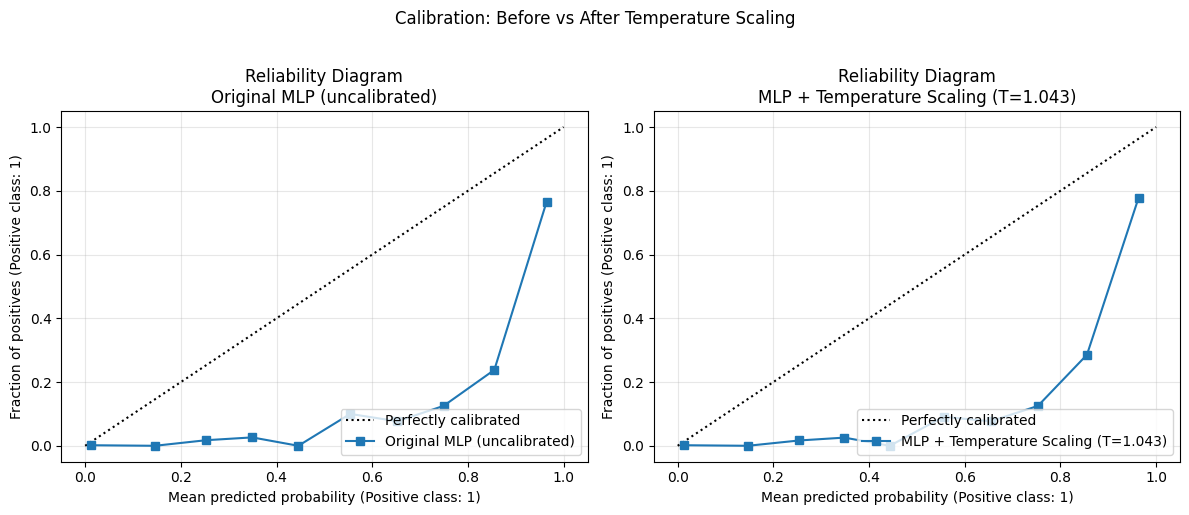

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, proba, name in [
    (axes[0], y_proba, 'Original MLP (uncalibrated)'),
    (axes[1], y_proba_temp, f'MLP + Temperature Scaling (T={T_opt:.3f})'),
]:
    CalibrationDisplay.from_predictions(
        y_test, proba, n_bins=10, ax=ax, name=name
    )
    ax.set_title(f'Reliability Diagram\n{name}')
    ax.grid(True, alpha=0.3)

plt.suptitle('Calibration: Before vs After Temperature Scaling', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

---
## 13. Brier Score

- Brier Score -
Baseline (naive): 0.032844
Original MLP: 0.042246  (skill: -0.2863)
MLP + Temperature Scaling: 0.042303  (skill: -0.2880)

NLL (log-loss) uncalibrated: 0.139550
NLL (log-loss) temp-scaled: 0.140243


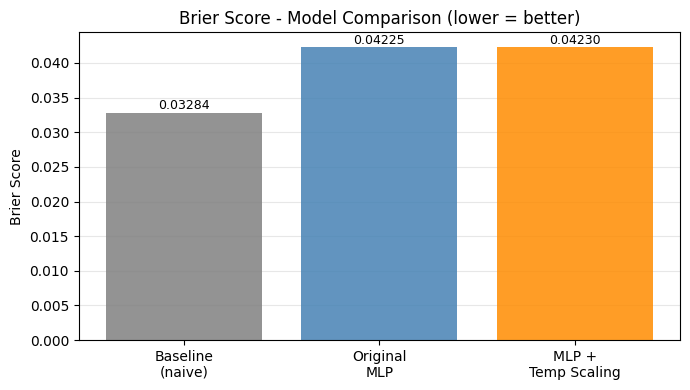

In [19]:
from sklearn.metrics import brier_score_loss

brier_orig  = brier_score_loss(y_test, y_proba)
brier_temp  = brier_score_loss(y_test, y_proba_temp)

brier_baseline = brier_score_loss(
    y_test, np.full_like(y_test, y_test.mean(), dtype=float)
)

def brier_skill(brier, baseline):
    return 1 - brier / baseline

print('- Brier Score -')
print(f'Baseline (naive): {brier_baseline:.6f}')
print(f'Original MLP: {brier_orig:.6f}  (skill: {brier_skill(brier_orig, brier_baseline):+.4f})')
print(f'MLP + Temperature Scaling: {brier_temp:.6f}  (skill: {brier_skill(brier_temp,  brier_baseline):+.4f})')
print()
print(f'NLL (log-loss) uncalibrated: {log_loss(y_test, y_proba):.6f}')
print(f'NLL (log-loss) temp-scaled: {log_loss(y_test, y_proba_temp):.6f}')

fig, ax = plt.subplots(figsize=(7, 4))
names  = ['Baseline\n(naive)', 'Original\nMLP', 'MLP +\nTemp Scaling']
scores = [brier_baseline, brier_orig, brier_temp]
colors = ['gray', 'steelblue', 'darkorange']
bars = ax.bar(names, scores, color=colors, alpha=0.85)
for bar, val in zip(bars, scores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.0005,
            f'{val:.5f}', ha='center', fontsize=9)
ax.set_title('Brier Score - Model Comparison (lower = better)')
ax.set_ylabel('Brier Score')
ax.yaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


---
## 14. AUC / AP Comparison - Calibrated Models

Model                    ROC-AUC   Avg Prec     Brier       NLL
--------------------------------------------------------------
Original MLP              0.9799     0.7909  0.042246  0.139550
MLP + Temp Scaling        0.9799     0.7909  0.042303  0.140243


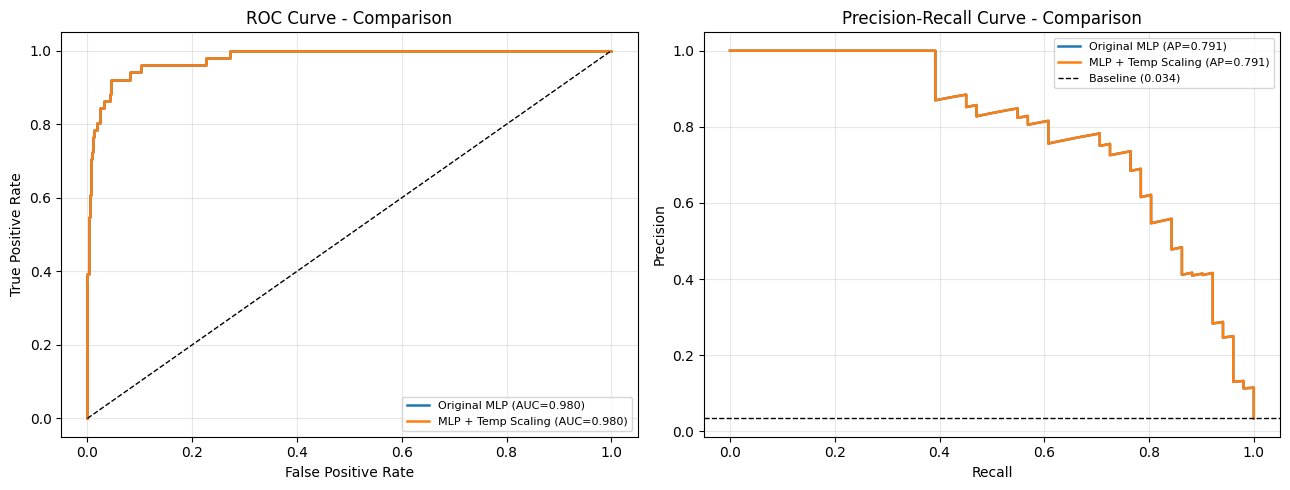

In [22]:
results = {
    'Original MLP': (
        y_proba,
        roc_auc_score(y_test, y_proba),
        average_precision_score(y_test, y_proba)
    ),
    'MLP + Temp Scaling': (
        y_proba_temp,
        roc_auc_score(y_test, y_proba_temp),
        average_precision_score(y_test, y_proba_temp)
    ),
}

briery = [brier_orig, brier_temp]

print(f'{"Model":<22} {"ROC-AUC":>9} {"Avg Prec":>10} {"Brier":>9} {"NLL":>9}')
print('-' * 62)
for (name, (_, auc, ap)), brier in zip(results.items(), briery):
    nll = log_loss(y_test, results[name][0])
    print(f'{name:<22} {auc:>9.4f} {ap:>10.4f} {brier:>9.6f} {nll:>9.6f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, (proba, auc, ap) in results.items():
    fpr_i, tpr_i, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr_i, tpr_i, lw=1.8, label=f'{name} (AUC={auc:.3f})')

    prec_i, rec_i, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec_i, prec_i, lw=1.8, label=f'{name} (AP={ap:.3f})')

axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_title('ROC Curve - Comparison')
axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

axes[1].axhline(y_test.mean(), color='k', linestyle='--', lw=1,
                label=f'Baseline ({y_test.mean():.3f})')
axes[1].set_title('Precision-Recall Curve - Comparison')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


---
## 15. Predicted Probability Distribution

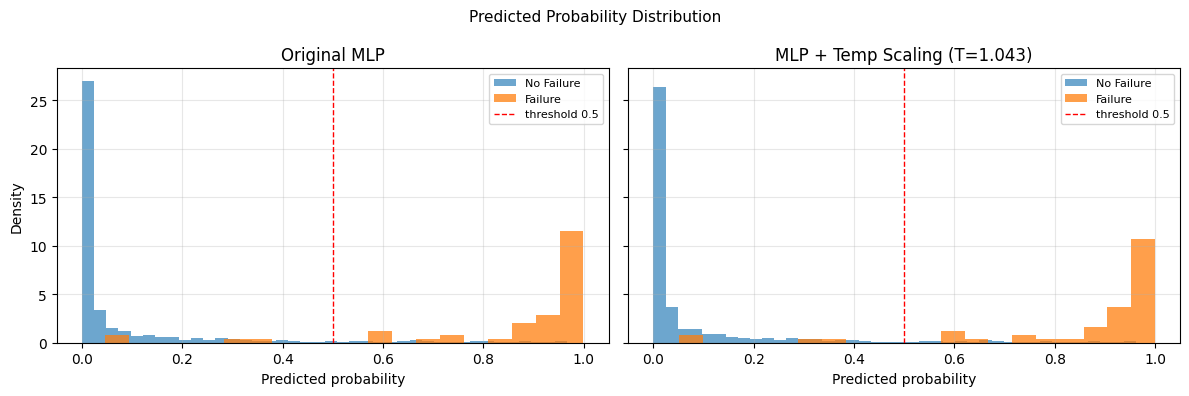

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

plot_data = [
    (y_proba, 'Original MLP', axes[0]),
    (y_proba_temp, f'MLP + Temp Scaling (T={T_opt:.3f})', axes[1]),
]

for proba, name, ax in plot_data:
    ax.hist(proba[y_test==0], bins=40, alpha=0.65, density=True, label='No Failure')
    ax.hist(proba[y_test==1], bins=20, alpha=0.75, density=True, label='Failure')
    ax.axvline(0.5, color='red', linestyle='--', lw=1, label='threshold 0.5')
    ax.set_title(name)
    ax.set_xlabel('Predicted probability')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel('Density')
plt.suptitle('Predicted Probability Distribution', fontsize=11)
plt.tight_layout()
plt.show()


---
## 16. Decision Threshold Optimization

Selected model for threshold analysis: Original MLP


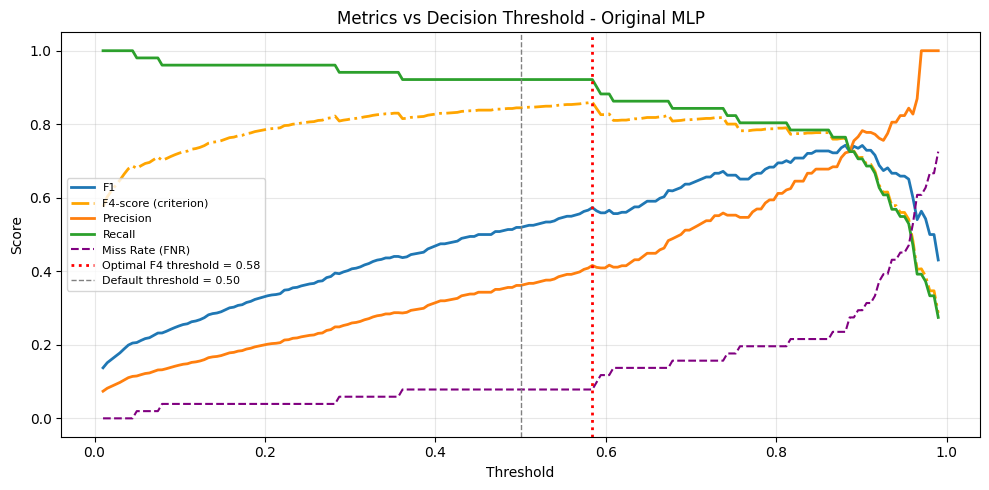


- Default threshold (0.50) -
              precision    recall  f1-score   support

  No Failure       1.00      0.94      0.97      1449
     Failure       0.36      0.92      0.52        51

    accuracy                           0.94      1500
   macro avg       0.68      0.93      0.74      1500
weighted avg       0.98      0.94      0.95      1500


- Optimal F4 threshold (0.58) -
              precision    recall  f1-score   support

  No Failure       1.00      0.95      0.98      1449
     Failure       0.42      0.92      0.57        51

    accuracy                           0.95      1500
   macro avg       0.71      0.94      0.77      1500
weighted avg       0.98      0.95      0.96      1500

Metric                    Threshold 0.50  Opt. Threshold     Change
------------------------------------------------------------------
F1-score                          0.5193          0.5732    +0.0538
F4-score                          0.8446          0.8601    +0.0155
Precision   

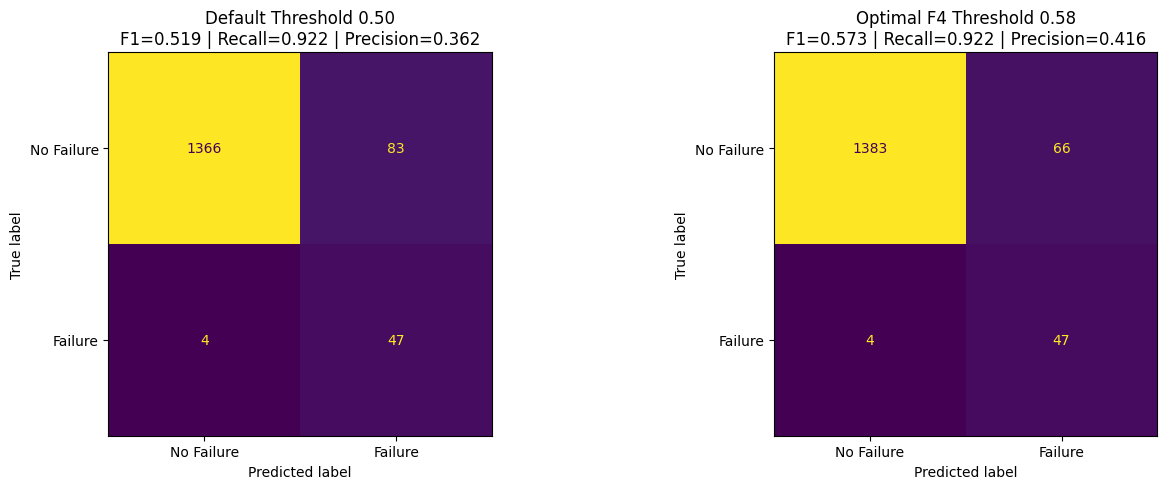

In [32]:
from sklearn.metrics import f1_score, fbeta_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

BETA = 4   # recall weighted 4× - undetected failure >> false alarm

all_variants = [
    ('Original MLP', y_proba, brier_orig),
    ('MLP + Temp Scaling', y_proba_temp, brier_temp),
]
best_name, best_proba, _ = min(all_variants, key=lambda x: x[2])
print(f'Selected model for threshold analysis: {best_name}')

thresholds = np.linspace(0.01, 0.99, 199)
f1s, fbs, precs, recs, fnrs = [], [], [], [], []

for t in thresholds:
    y_t = (best_proba >= t).astype(int)
    f1s.append(f1_score(y_test, y_t, zero_division=0))
    fbs.append(fbeta_score(y_test, y_t, beta=BETA, zero_division=0))
    precs.append(precision_score(y_test, y_t, zero_division=0))
    recs.append(recall_score(y_test, y_t, zero_division=0))
    cm_t = confusion_matrix(y_test, y_t)
    tn_t, fp_t, fn_t, tp_t = cm_t.ravel() if cm_t.size == 4 else (0, 0, 0, 0)
    fnrs.append(fn_t / (fn_t + tp_t + 1e-9))

best_t_idx = np.argmax(fbs)
best_t = thresholds[best_t_idx]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(thresholds, f1s,   lw=2, label='F1')
ax.plot(thresholds, fbs,   lw=2, linestyle='-.', color='orange', label=f'F{BETA}-score (criterion)')
ax.plot(thresholds, precs, lw=2, label='Precision')
ax.plot(thresholds, recs,  lw=2, label='Recall')
ax.plot(thresholds, fnrs,  lw=1.5, linestyle='--', color='purple', label='Miss Rate (FNR)')
ax.axvline(best_t, color='red', linestyle=':', lw=2,
           label=f'Optimal F{BETA} threshold = {best_t:.2f}')
ax.axvline(0.5, color='gray', linestyle='--', lw=1, label='Default threshold = 0.50')
ax.set_title(f'Metrics vs Decision Threshold - {best_name}')
ax.set_xlabel('Threshold'); ax.set_ylabel('Score')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'\n- Default threshold (0.50) -')
y_default = (best_proba >= 0.50).astype(int)
print(classification_report(y_test, y_default, target_names=['No Failure', 'Failure']))

print(f'\n- Optimal F{BETA} threshold ({best_t:.2f}) -')
y_optimal = (best_proba >= best_t).astype(int)
print(classification_report(y_test, y_optimal, target_names=['No Failure', 'Failure']))

f1_def   = f1_score(y_test, y_default, zero_division=0)
prec_def = precision_score(y_test, y_default, zero_division=0)
rec_def  = recall_score(y_test, y_default, zero_division=0)
fb_def   = fbeta_score(y_test, y_default, beta=BETA, zero_division=0)

f1_opt   = f1_score(y_test, y_optimal, zero_division=0)
prec_opt = precision_score(y_test, y_optimal, zero_division=0)
rec_opt  = recall_score(y_test, y_optimal, zero_division=0)
fb_opt   = fbeta_score(y_test, y_optimal, beta=BETA, zero_division=0)

cm_def = confusion_matrix(y_test, y_default)
tn_def, fp_def, fn_def, tp_def = cm_def.ravel()
fnr_def = fn_def / (fn_def + tp_def + 1e-9)

cm_opt = confusion_matrix(y_test, y_optimal)
tn_opt, fp_opt, fn_opt, tp_opt = cm_opt.ravel()
fnr_opt = fn_opt / (fn_opt + tp_opt + 1e-9)

print(f"{'Metric':<25} {'Threshold 0.50':>14} {'Opt. Threshold':>15} {'Change':>10}")
print("-" * 66)
for label, v_def, v_opt in [
    ("F1-score", f1_def, f1_opt),
    (f"F{BETA}-score", fb_def, fb_opt),
    ("Precision", prec_def, prec_opt),
    ("Recall", rec_def, rec_opt),
    ("Miss Rate (FNR)", fnr_def, fnr_opt),
]:
    print(f"{label:<25} {v_def:>14.4f} {v_opt:>15.4f} {v_opt - v_def:>+10.4f}")

for label, v_def, v_opt in [
    ("True Positives",  tp_def, tp_opt),
    ("False Positives", fp_def, fp_opt),
    ("False Negatives", fn_def, fn_opt),
    ("True Negatives",  tn_def, tn_opt),
]:
    print(f"{label:<25} {v_def:>14} {v_opt:>15} {v_opt - v_def:>+10}")

print("\nInterpretation:")
print("The MLP model achieved the best results among the tested variants, while additional optimization techniques did not provide any significant improvement in classification performance. The best results were obtained using the baseline model with an appropriately selected decision threshold (0.58). Adjusting the threshold mainly improved precision and F1-score while maintaining a very high recall (92.16%), which means effective failure detection with a reduced number of false alarms.")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay(cm_def, display_labels=['No Failure', 'Failure']).plot(ax=axes[0], colorbar=False)
axes[0].set_title(f'Default Threshold 0.50\nF1={f1_def:.3f} | Recall={rec_def:.3f} | Precision={prec_def:.3f}')
ConfusionMatrixDisplay(cm_opt, display_labels=['No Failure', 'Failure']).plot(ax=axes[1], colorbar=False)
axes[1].set_title(f'Optimal F{BETA} Threshold {best_t:.2f}\nF1={f1_opt:.3f} | Recall={rec_opt:.3f} | Precision={prec_opt:.3f}')
plt.tight_layout()
plt.show()


---
## 17. Summary

In [30]:
print('Summary - MLP + Temperature Scaling')
print(f'{"Model":<25} {"ROC-AUC":>9} {"Brier":>10} {"Skill":>8} {"NLL":>9}')
print(f'{"-"*63}')
for (name, (proba, auc, ap)), brier in zip(results.items(), briery):
    skill = 1 - brier / brier_baseline
    nll   = log_loss(y_test, proba)
    print(f'{name:<25} {auc:>9.4f} {brier:>10.6f} {skill:>8.4f} {nll:>9.6f}')
print()
print(f'Best architecture (hidden_layer_sizes): {best_arch}')
print(f'Fitted temperature: T = {T_opt:.4f}')
print(f'Selected final model: {best_name}')
print(f'Optimal decision threshold (max F{BETA}): {best_t:.2f}')


Summary - MLP + Temperature Scaling
Model                       ROC-AUC      Brier    Skill       NLL
---------------------------------------------------------------
Original MLP                 0.9799   0.042246  -0.2863  0.139550
MLP + Temp Scaling           0.9799   0.042303  -0.2880  0.140243

Best architecture (hidden_layer_sizes): (64, 32)
Fitted temperature: T = 1.0429
Selected final model: Original MLP
Optimal decision threshold (max F4): 0.58
